## 1. What is Multimodal RAG?

- Multimodal: Working with multiple types of data, such as text, images, audio, video, and tables or charts.

- RAG (Retrieval-Augmented Generation): Retrieving relevant information from your own knowledge source and providing it to an LLM to generate a grounded answer.

- Multimodal RAG: A RAG system that can retrieve and reason over different data types, including text and images, rather than relying only on text.

## Traditional Text-Based RAG

A PDF contains paragraphs about a company's quarterly revenue. The system extracts the text, splits it into chunks, creates embeddings, retrieves relevant chunks and sends them to an LLM.

Limitation: charts, diagrams and screenshots may be missed if their information is not represented in extracted text.

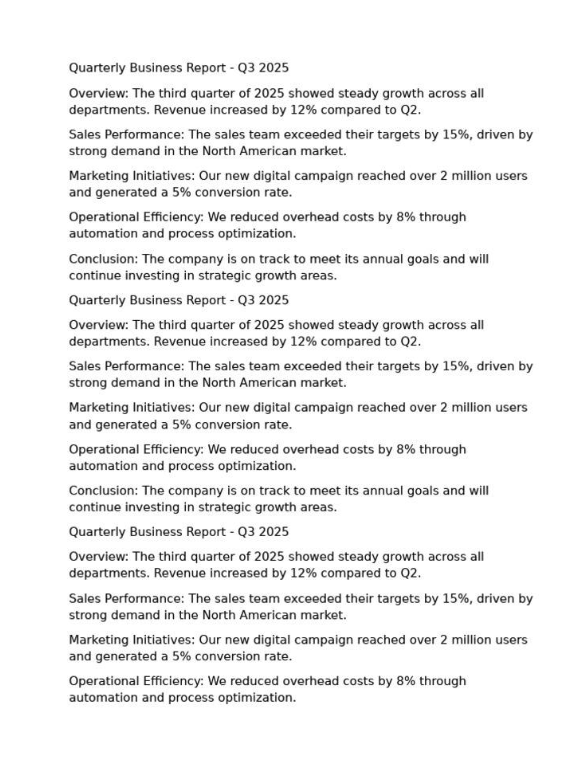

## Multimodal RAG

The system processes both the paragraphs and the visual content. It can retrieve a relevant chart alongside the associated text and use a vision-capable LLM to answer questions about them.

Advantage: answers can use information that exists in either text or visual content.

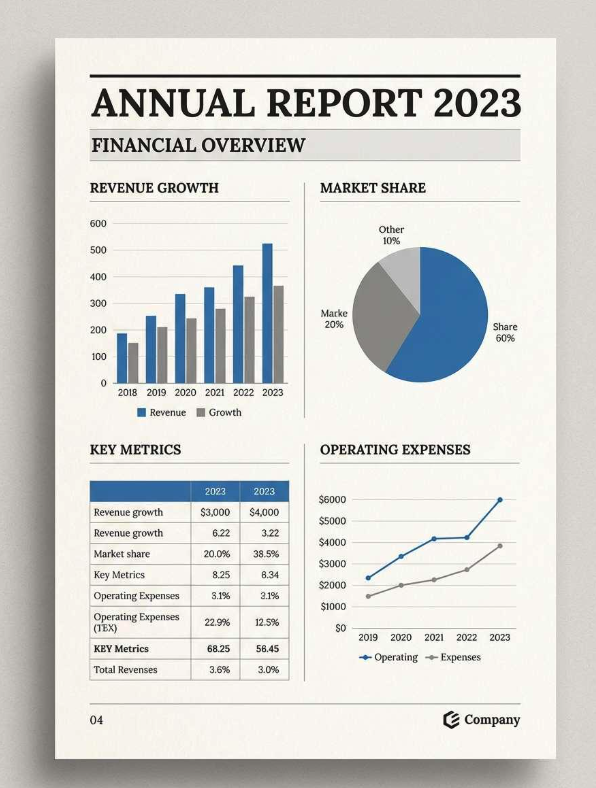

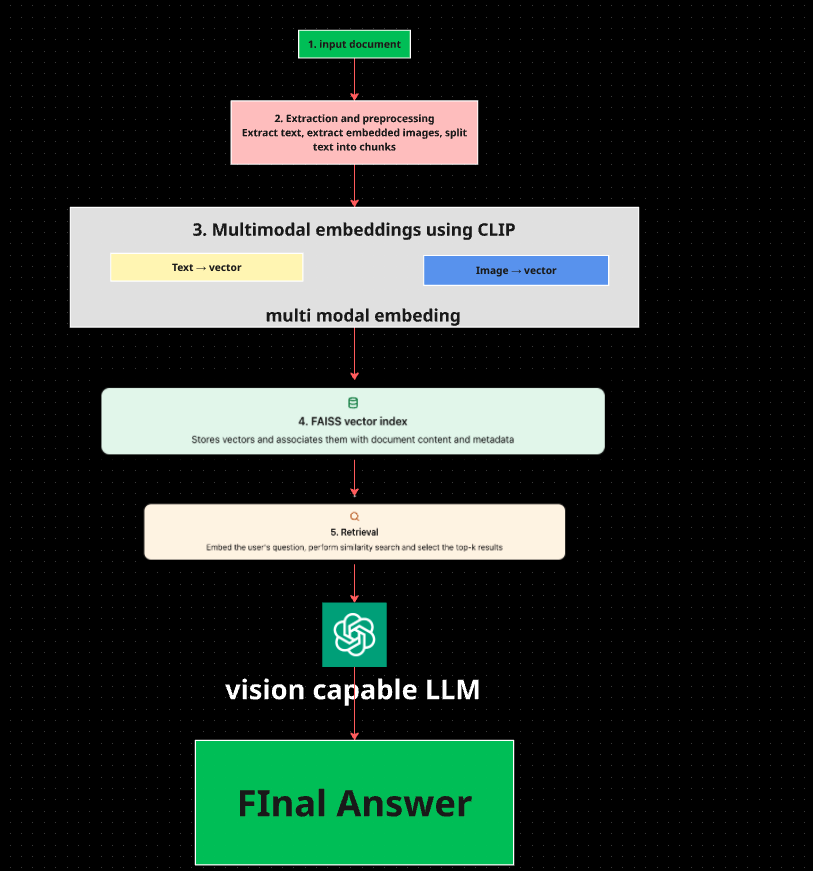

CLIP stands for Contrastive Language–Image Pre-training.

It is a multimodal AI model developed by OpenAI that learns to connect text and images in a shared embedding space.
How CLIP works in your Multimodal RAG project
- Text: Converts a text query into a numerical vector (embedding).
- Image: Converts an image into a numerical vector.
- Similarity: Compares the vectors to find semantically related text and images.
For example:







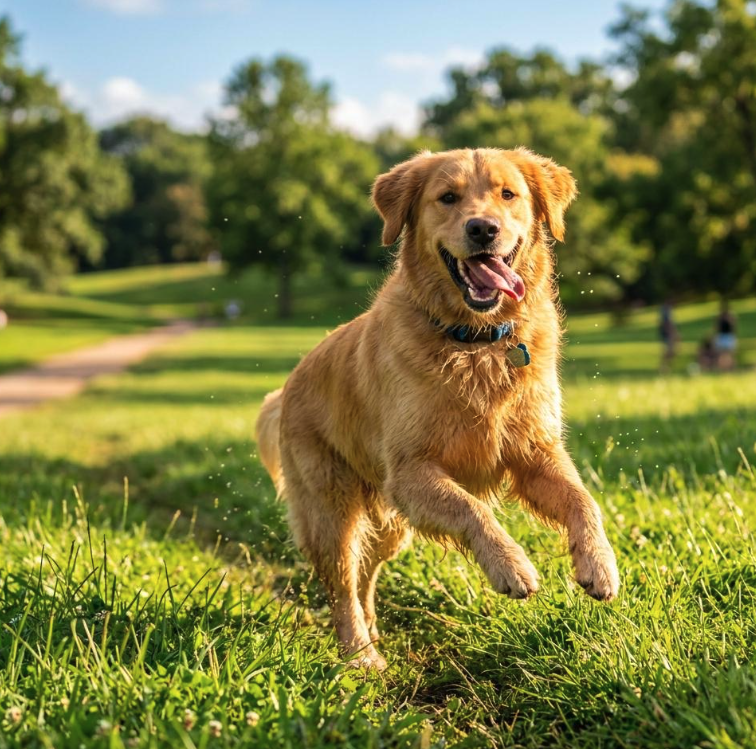

Image input

A photograph of a golden retriever playing in a park.


Text query: "A dog playing in a park"

CLIP can map the image and text into a shared vector space, where their embeddings should be relatively similar.

In your Multimodal RAG architecture:
1. CLIP creates embeddings for text and images.
2. FAISS retrieves the most relevant content for a user's question.
3. The vision-capable LLM analyses the retrieved text and images.
4. The LLM generates the final answer.

In [42]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [43]:
import os
import io
import base64
from pathlib import Path

import fitz
import numpy as np
import torch
from PIL import Image

from transformers import CLIPProcessor, CLIPModel

from langchain_community.document_loaders import (
    DirectoryLoader,
    PyMuPDFLoader,
    TextLoader
)

from langchain_core.documents import Document
from langchain_core.messages import HumanMessage
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_openai import ChatOpenAI

In [44]:
# Loading stage

pdf_loader = DirectoryLoader(
    "data",
    glob="**/*.pdf",
    loader_cls=PyMuPDFLoader,
    show_progress=True
)

pdf_documents = pdf_loader.load()

# Load all text files under data/
text_loader = DirectoryLoader(
    "data",
    glob="**/*.txt",
    loader_cls=TextLoader,
    loader_kwargs={"encoding": "utf-8"},
    show_progress=True
)

text_documents = text_loader.load()

100%|██████████| 2/2 [00:00<00:00, 2484.04it/s]


In [45]:
# Combine all extracted text documents
documents = pdf_documents + text_documents

print("Total PDF pages and text documents:", len(documents))

Total PDF pages and text documents: 520


- DirectoryLoader finds files matching each pattern.
- PyMuPDFLoader extracts text and page metadata from PDFs.
- TextLoader reads the .txt files.
- documents holds the extracted content.

In [46]:
# Create a text splitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=100
)

# Split PDF and TXT content into smaller documents
text_chunks = text_splitter.split_documents(documents)

print("Total text chunks:", len(text_chunks))

Total text chunks: 2819


# Load the CLIP model

In [47]:
# Load the pretrained CLIP model
clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
)

# Load the matching text/image processor
clip_processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

# Use inference mode, not training mode
clip_model.eval()

print("CLIP model loaded")

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 48643.07it/s]


CLIP model loaded


# Create the embedding functions

In [48]:
def embed_image(image):
    inputs = clip_processor(images=image, return_tensors="pt")
    
    with torch.no_grad():
        outputs = clip_model.get_image_features(**inputs)
        
        # If outputs is a model output object, extract the tensor:
        if hasattr(outputs, "image_embeds"):
            vector = outputs.image_embeds
        elif hasattr(outputs, "pooler_output"):
            vector = outputs.pooler_output
        elif not isinstance(outputs, torch.Tensor):
            vector = outputs[0]
        else:
            vector = outputs

        # Normalize embedding
        vector = vector / vector.norm(p=2, dim=-1, keepdim=True)

    return vector.squeeze().cpu().numpy()

In [39]:
import torch

def embed_text(text, batch_size=32):
    """
    Computes normalized CLIP text embeddings for a single string or a list of strings.
    Automatically matches the model's device and handles batching.
    """
    is_single_input = isinstance(text, str)
    texts = [text] if is_single_input else text
    
    device = next(clip_model.parameters()).device
    all_embeddings = []

    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i : i + batch_size]

            # Tokenize batch and push directly to model device
            inputs = clip_processor(
                text=batch_texts,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=77
            ).to(device)

            # Generate projected text embeddings and L2-normalize them
            outputs = clip_model.get_text_features(**inputs)
            features = outputs.pooler_output
            features = torch.nn.functional.normalize(features, p=2, dim=-1)

            all_embeddings.append(features.cpu())

    # Concatenate all batches
    final_vectors = torch.cat(all_embeddings, dim=0).numpy()

    # Return a 1D array if a single string was passed, otherwise a 2D array
    return final_vectors[0] if is_single_input else final_vectors

# Load all standalone images and extract images from PDFs

In [49]:
# Store the original image data for the LLM
image_data_store = {}

# Store documents representing images
image_documents = []

# Store the corresponding image vectors
image_embeddings = []


def add_image(image, image_id, source, page=None):
    """
    Store an image, create its CLIP embedding,
    and add an image document to our collection.
    """

    # Convert the image to RGB
    image = image.convert("RGB")

    # Convert it to PNG bytes
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")

    # Save the image in Base64 format
    image_data_store[image_id] = base64.b64encode(
        buffer.getvalue()
    ).decode("utf-8")

    # Generate the image embedding
    vector = embed_image(image)     
 
    # Create a document containing the image reference
    metadata = {
        "type": "image",
        "image_id": image_id,
        "source": source
    }

    if page is not None:
        metadata["page"] = page

    image_doc = Document(
        page_content=f"[Image: {image_id}]",
        metadata=metadata
    )

    # Keep the document and vector together
    image_documents.append(image_doc)
    image_embeddings.append(vector)

In [50]:
# Supported standalone image extensions
image_extensions = {
    ".png", ".jpg", ".jpeg", ".webp", ".bmp"
}

# Discover all images recursively under data/
for image_path in Path("data").rglob("*"):

    if image_path.is_file() and image_path.suffix.lower() in image_extensions:

        # Open the image
        with Image.open(image_path) as image:

            # Add it to our multimodal collection
            add_image(
                image=image,
                image_id=str(image_path),
                source=str(image_path)
            )

print("Standalone images loaded:", len(image_documents))


Standalone images loaded: 2


In [41]:
# Discover every PDF under data/
pdf_paths = list(Path("data").rglob("*.pdf"))

for pdf_path in pdf_paths:

    # Open the PDF
    pdf = fitz.open(pdf_path)

    for page_index, page in enumerate(pdf):

        # Find embedded image objects on the current page
        for image_index, image_info in enumerate(
            page.get_images(full=True)
        ):

            try:
                # Get the PDF image reference
                xref = image_info[0]

                # Extract the image bytes
                extracted = pdf.extract_image(xref)
                image_bytes = extracted["image"]

                # Convert the bytes to a PIL image
                with Image.open(io.BytesIO(image_bytes)) as image:

                    # Create a unique identifier for this PDF image
                    image_id = (
                        f"{pdf_path.stem}_page_{page_index + 1}"
                        f"_image_{image_index + 1}"
                    )

                    # Store and embed the image
                    add_image(
                        image=image,
                        image_id=image_id,
                        source=str(pdf_path),
                        page=page_index + 1
                    )

            except Exception as error:
                print(
                    f"Could not process image on "
                    f"{pdf_path}, page {page_index + 1}: {error}"
                )

    pdf.close()

print("Total images processed:", len(image_documents))

Total images processed: 154


In [51]:
batch_size = 64
text_embeddings = []

for i in range(0, len(text_chunks), batch_size):
    batch = text_chunks[i : i + batch_size]
    
    for chunk in batch:
        chunk.metadata["type"] = "text"
        
    batch_texts = [chunk.page_content for chunk in batch]
    vectors = embed_text(batch_texts)
    
    text_embeddings.extend(vectors)

print("Text chunks embedded:", len(text_embeddings))


Text chunks embedded: 2819


# Combine the text and image documents

In [52]:
# Start with the text documents and their embeddings
all_docs = list(text_chunks)
all_embeddings = list(text_embeddings)

# Add the image documents and embeddings
all_docs.extend(image_documents)
all_embeddings.extend(image_embeddings)

# Validate that every document has one vector
assert len(all_docs) == len(all_embeddings)

print("Total documents:", len(all_docs))
print("Total vectors:", len(all_embeddings))
print("Embedding dimension:", len(all_embeddings[0]))

Total documents: 2821
Total vectors: 2821
Embedding dimension: 512


In [54]:
from langchain_core.embeddings import Embeddings


class CLIPEmbeddings(Embeddings):
    """
    Adapter that lets LangChain use our existing CLIP functions.
    """

    def embed_documents(self, texts):
        # Create a vector for every text
        return [
            embed_text(text).tolist()
            for text in texts
        ]

    def embed_query(self, text):
        # Create a vector for the user's query
        return embed_text(text).tolist()


# Create the embedding adapter
clip_embeddings = CLIPEmbeddings()


# Pair each document's content with its precomputed vector
text_embedding_pairs = []

for doc_item, vector in zip(all_docs, all_embeddings):

    text_embedding_pairs.append(
        (doc_item.page_content, vector.tolist())
    )


# Build FAISS from the precomputed CLIP vectors
vector_store = FAISS.from_embeddings(
    text_embeddings=text_embedding_pairs,
    embedding=clip_embeddings,
    metadatas=[
        doc_item.metadata
        for doc_item in all_docs
    ]
)

print("FAISS index created successfully")

FAISS index created successfully


In [55]:
def retrieve_multimodal(query, k=5):
    """
    Find the top-k documents relevant to a question.
    Results may include text, images, or both.
    """

    # Convert the question into a CLIP text vector
    query_vector = embed_text(query)

    # Search FAISS using the query vector
    retrieved_docs = vector_store.similarity_search_by_vector(
        embedding=query_vector.tolist(),
        k=k
    )

    # Inspect the results
    for doc_item in retrieved_docs:

        print("Type:", doc_item.metadata.get("type"))
        print("Source:", doc_item.metadata.get("source", "N/A"))
        print("Page:", doc_item.metadata.get("page", "N/A"))
        print("Content:", doc_item.page_content[:150])
        print("-" * 50)

    return retrieved_docs

In [56]:
query = "Explain the architecture diagram"

retrieved_docs = retrieve_multimodal(
    query=query,
    k=5
)

Type: text
Source: data/documents/aws_notes.pdf
Page: 360
Content: contains all changes to your resource configurations.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 99
Content: such as:
Applying patches and updates to the OS
Enrolling in a directory service
Installing application software
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 145
Content: and the changes will take effect immediately.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 470
Content: scalability and overall performance of their systems.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 112
Content: is available from within the instance. It can be obtained through an HTTP call to a specific IP
address.
--------------------------------------------------


In [57]:
def create_multimodal_message(query, retrieved_docs):
    """
    Build one message containing retrieved text and images.
    """

    # Start with the user's question
    content = [
        {
            "type": "text",
            "text": (
                f"Question: {query}\n\n"
                "Use the retrieved evidence to answer the question. "
                "If the evidence is insufficient, say so."
            )
        }
    ]

    # Process each retrieved document
    for doc_item in retrieved_docs:

        doc_type = doc_item.metadata.get("type")

        # Add retrieved text
        if doc_type == "text":

            page = doc_item.metadata.get("page", "N/A")
            source = doc_item.metadata.get("source", "N/A")

            content.append({
                "type": "text",
                "text": (
                    f"\nRetrieved text from {source}, page {page}:\n"
                    f"{doc_item.page_content}"
                )
            })

        # Add the actual retrieved image
        elif doc_type == "image":

            image_id = doc_item.metadata.get("image_id")

            if image_id in image_data_store:

                content.append({
                    "type": "text",
                    "text": (
                        f"\nRetrieved image: {image_id}"
                    )
                })

                content.append({
                    "type": "image_url",
                    "image_url": {
                        "url": (
                            "data:image/png;base64,"
                            + image_data_store[image_id]
                        )
                    }
                })

    # Return a multimodal LangChain message
    return HumanMessage(content=content)

In [58]:
from langchain_openai import ChatOpenAI

# Initialize the vision-capable LLM
llm = ChatOpenAI(
    model="gpt-4.1",
    temperature=0
)

print("LLM initialized")

LLM initialized


In [59]:
def multimodal_rag(query, k=5):
    """
    Complete Multimodal RAG pipeline.

    1. Retrieve relevant documents
    2. Prepare text and image context
    3. Send the context to the LLM
    4. Return the generated answer
    """

    # STEP 1: Retrieve relevant text and image documents
    retrieved_docs = retrieve_multimodal(
        query=query,
        k=k
    )

    # STEP 2: Create the multimodal message
    message = create_multimodal_message(
        query=query,
        retrieved_docs=retrieved_docs
    )

    # STEP 3: Send the question and retrieved context to the LLM
    response = llm.invoke([message])

    # STEP 4: Return the final answer
    return response.content

In [61]:
# Ask a question about your documents and images
question = "Explain the security group"

# Retrieve evidence and generate an answer
answer = multimodal_rag(question, k=5)

print("\nFinal Answer:")
print(answer)

Type: text
Source: data/documents/aws_notes.pdf
Page: 145
Content: and the changes will take effect immediately.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 360
Content: contains all changes to your resource configurations.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 470
Content: scalability and overall performance of their systems.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 274
Content: Congratulations! In this exercise, you created a new queue. You will publish to this
queue in the following exercise.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 42
Content: their data is physically located, allowing them to meet regional compliance and data
residency requirements.
--------------------------------------------------

Final Answer:
The retrieved e

In [62]:
questions = [
    "What is multimodal RAG?",
    "Explain the architecture shown in the PDF.",
    "What does the revenue chart show?",
    "What information is available about AWS architecture?"
]

for question in questions:

    print("\nQuestion:", question)
    print("=" * 60)

    answer = multimodal_rag(question, k=5)

    print("\nAnswer:")
    print(answer)


Question: What is multimodal RAG?
Type: text
Source: data/documents/aws_notes.pdf
Page: 360
Content: contains all changes to your resource configurations.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 470
Content: scalability and overall performance of their systems.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 145
Content: and the changes will take effect immediately.
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 177
Content: arn:aws:autoscaling:us-east-1:123456789012:scalingPolicy:12345678-90ab-cdef- 
1234567890ab:autoScalingGroupName/myASG:policyName/CPULoadScaleOut --uni
--------------------------------------------------
Type: text
Source: data/documents/aws_notes.pdf
Page: 177
Content: "Name=AutoScalingGroupName, Value=myASG" --evaluation-periods 1 --alarm-actions  
arn:aws:autoscaling:us-east-1:123456789